# STRAVA FITNESS DATA ANALYTICS CASE STUDY

## Bellabeat Smart Device Usage Analysis

### Prepared By: Ayush Dash

### Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Google Colab

### Datasets Used
- dailyActivity_merged.csv
- sleepDay_merged.csv
- weightLogInfo_merged.csv
- hourlySteps_merged.csv

### Project Type
Data Analytics Case Study

In [1]:
from google.colab import files

uploaded = files.upload()

Saving dailyActivity_merged.csv to dailyActivity_merged.csv
Saving hourlySteps_merged.csv to hourlySteps_merged.csv
Saving sleepDay_merged.csv to sleepDay_merged.csv
Saving weightLogInfo_merged.csv to weightLogInfo_merged.csv


# Business Task

Bellabeat wants to understand how consumers use smart fitness devices. The objective is to analyze user activity, sleep behavior, weight records, and hourly activity patterns to generate insights that can support marketing strategies and product improvements.

### Key Questions

1. How active are Bellabeat users?
2. What are users' sleeping habits?
3. Is there a relationship between activity and calorie burn?
4. When are users most active?
5. How can Bellabeat improve engagement?

# **Data Loading**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

daily_activity = pd.read_csv('/content/dailyActivity_merged.csv')
sleep = pd.read_csv('/content/sleepDay_merged.csv')
weight = pd.read_csv('/content/weightLogInfo_merged.csv')
hourly_steps = pd.read_csv('/content/hourlySteps_merged.csv')

# **Dataset Overview**

In [3]:
print("Daily Activity:", daily_activity.shape)
print("Sleep:", sleep.shape)
print("Weight:", weight.shape)
print("Hourly Steps:", hourly_steps.shape)

Daily Activity: (940, 15)
Sleep: (413, 5)
Weight: (67, 8)
Hourly Steps: (22099, 3)


### Observation

The datasets contain daily activity metrics, sleep records, weight logs, and hourly step counts collected from Fitbit users. These datasets will be used to understand user behavior patterns.

# **Data Cleaning**

i. Missing Values

In [9]:
daily_activity.isnull().sum()

,0
Id,0
ActivityDate,0
TotalSteps,0
TotalDistance,0
TrackerDistance,0
LoggedActivitiesDistance,0
VeryActiveDistance,0
ModeratelyActiveDistance,0
LightActiveDistance,0
SedentaryActiveDistance,0


In [10]:
sleep.isnull().sum()

,0
Id,0
SleepDay,0
TotalSleepRecords,0
TotalMinutesAsleep,0
TotalTimeInBed,0


In [11]:
weight.isnull().sum()

,0
Id,0
Date,0
WeightKg,0
WeightPounds,0
Fat,65
BMI,0
IsManualReport,0
LogId,0


In [12]:
hourly_steps.isnull().sum()

,0
Id,0
ActivityHour,0
StepTotal,0


ii. Duplicates

In [13]:
print(sleep.duplicated().sum())
print(weight.duplicated().sum())

0
0


iii. Remove Duplicates

In [14]:
sleep.drop_duplicates(inplace=True)

iv. Date Conversion

In [15]:
daily_activity['ActivityDate'] = pd.to_datetime(
    daily_activity['ActivityDate']
)

sleep['SleepDay'] = pd.to_datetime(
    sleep['SleepDay']
)

hourly_steps['ActivityHour'] = pd.to_datetime(
    hourly_steps['ActivityHour']
)

/tmp/ipykernel_2059/87718596.py:5: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  sleep['SleepDay'] = pd.to_datetime(
/tmp/ipykernel_2059/87718596.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  hourly_steps['ActivityHour'] = pd.to_datetime(


### Data Cleaning Summary

The datasets were examined for missing values, duplicate records, and incorrect data types.

Date columns were converted to datetime format to support time-series analysis.

# **KPI Section**

In [16]:
avg_steps = daily_activity['TotalSteps'].mean()
print("Average Daily Steps:", round(avg_steps))

Average Daily Steps: 7638


In [17]:
avg_calories = daily_activity['Calories'].mean()
print("Average Calories Burned:", round(avg_calories))

Average Calories Burned: 2304


In [18]:
avg_distance = daily_activity['TotalDistance'].mean()
print("Average Distance:", round(avg_distance,2))

Average Distance: 5.49


### KPI Insight

These metrics provide a high-level overview of user activity and fitness behavior across the dataset.

# **Activity Analysis**

a. Most Active Users

In [19]:
most_active = (
    daily_activity
    .groupby('Id')['TotalSteps']
    .sum()
    .sort_values(ascending=False)
)

most_active.head(10)

,TotalSteps
Id,
8877689391,497241
8053475328,457662
1503960366,375619
2022484408,352490
4388161847,335232
3977333714,329537
6962181067,303639
7007744171,294409
7086361926,290525


b. Least Active Users

In [20]:
least_active = (
    daily_activity
    .groupby('Id')['TotalSteps']
    .sum()
    .sort_values()
)

least_active.head(10)

,TotalSteps
Id,
4057192912,15352
1927972279,28400
8792009665,53758
6775888955,65512
4020332650,70284
1844505072,79982
8253242879,123161
3372868164,137233
2320127002,146223


# **User Segmentation**

In [21]:
def classify_user(steps):

    if steps < 5000:
        return 'Sedentary'

    elif steps < 10000:
        return 'Moderately Active'

    else:
        return 'Highly Active'

In [22]:
daily_activity['ActivityLevel'] = (
    daily_activity['TotalSteps']
    .apply(classify_user)
)

In [23]:
activity_distribution = (
    daily_activity['ActivityLevel']
    .value_counts(normalize=True)*100
)

activity_distribution

,proportion
ActivityLevel,
Moderately Active,35.531915
Highly Active,32.234043
Sedentary,32.234043


### Business Insight

User segmentation reveals the proportion of inactive, moderately active, and highly active users.

This information can be used to create personalized engagement strategies.

# **Correlation Analysis**

In [25]:
daily_activity[
[
'TotalSteps',
'Calories',
'VeryActiveMinutes'
]
].corr()

,TotalSteps,Calories,VeryActiveMinutes
TotalSteps,1.000000,0.591568,0.667079
Calories,0.591568,1.000000,0.615838
VeryActiveMinutes,0.667079,0.615838,1.000000


### Insight

A strong positive correlation between steps and calories indicates that increased physical activity contributes to higher energy expenditure.

# **Time-Based Analysis**

In [26]:
hourly_steps['Hour'] = (
    hourly_steps['ActivityHour']
    .dt.hour
)

In [27]:
hourly_activity = (
    hourly_steps
    .groupby('Hour')['StepTotal']
    .mean()
)

hourly_activity

,StepTotal
Hour,
0,42.188437
1,23.102894
2,17.110397
3,6.426581
4,12.699571
5,43.869099
6,178.508056
7,306.049409
8,427.544576


### Insight

Identifying peak activity hours helps Bellabeat optimize notification timing and engagement campaigns.

#  Data Visualization

**A. Histogram of Daily Steps**

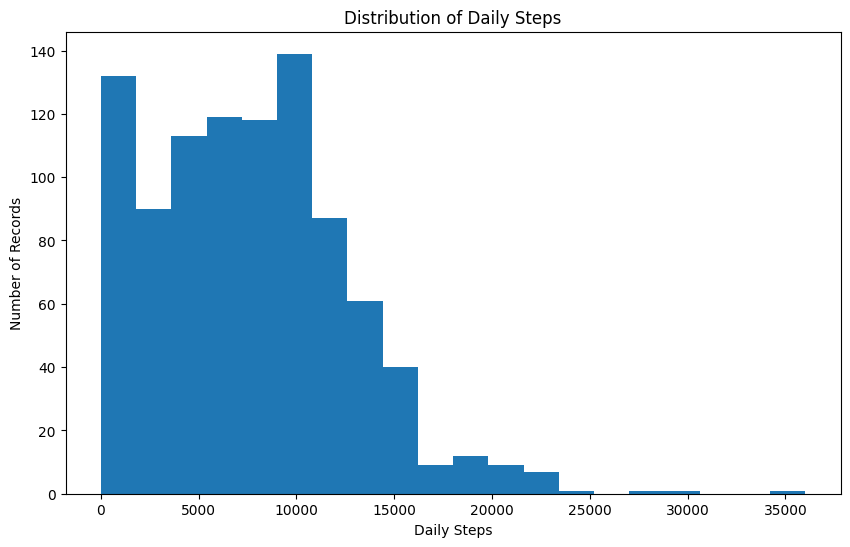

In [28]:
plt.figure(figsize=(10,6))

plt.hist(
    daily_activity['TotalSteps'],
    bins=20
)

plt.title('Distribution of Daily Steps')
plt.xlabel('Daily Steps')
plt.ylabel('Number of Records')

plt.show()

### Insight

The distribution of daily steps helps identify overall activity behavior among users.

The chart reveals whether most users achieve recommended activity levels or remain below fitness targets.

**B. Activity Level Distribution**

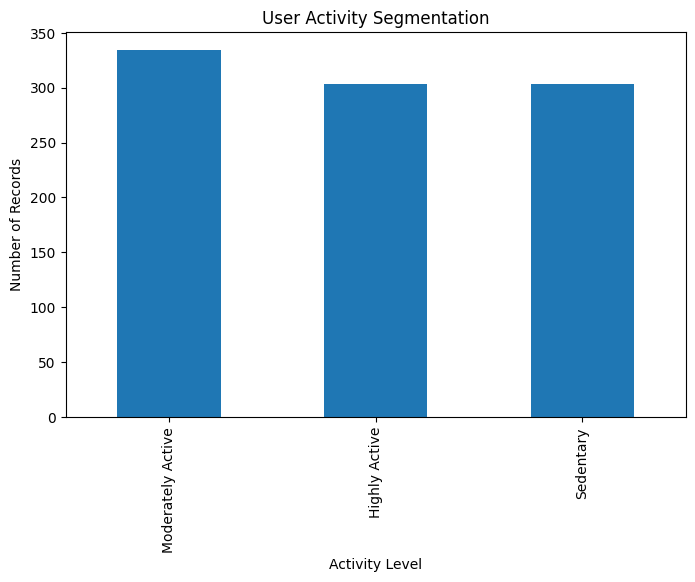

In [29]:
activity_distribution = (
    daily_activity['ActivityLevel']
    .value_counts()
)

plt.figure(figsize=(8,5))

activity_distribution.plot(kind='bar')

plt.title('User Activity Segmentation')
plt.xlabel('Activity Level')
plt.ylabel('Number of Records')

plt.show()

### Insight

A significant concentration of users in sedentary or moderately active categories indicates opportunities for Bellabeat to promote activity-based engagement programs.

 **C. Top 10 Active Users**

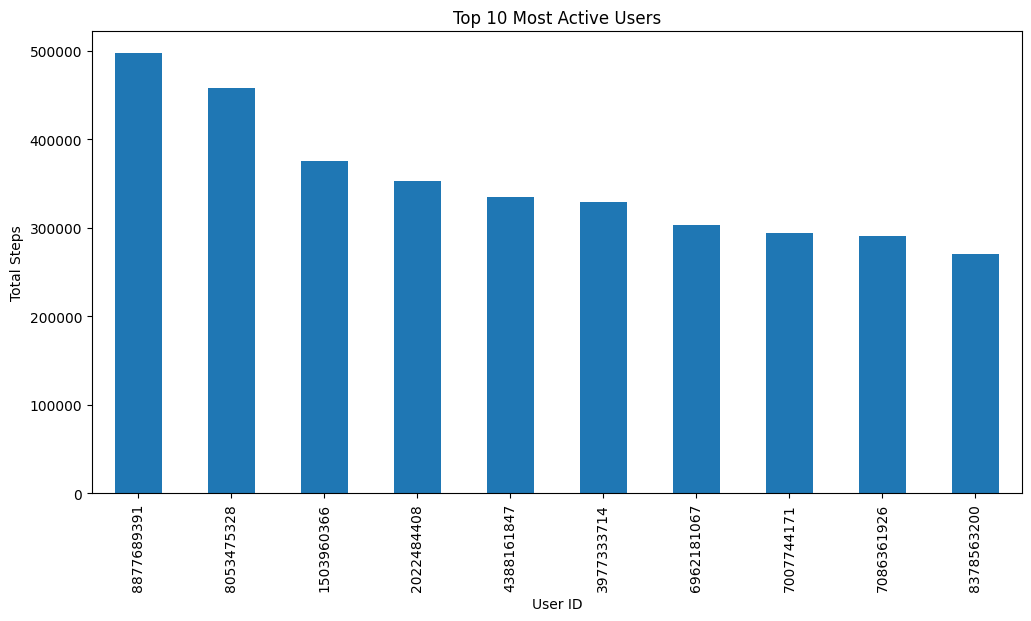

In [30]:
top_users = (
    daily_activity
    .groupby('Id')['TotalSteps']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))

top_users.plot(kind='bar')

plt.title('Top 10 Most Active Users')
plt.xlabel('User ID')
plt.ylabel('Total Steps')

plt.show()

### Insight

The most active users represent highly engaged customers who may serve as ideal candidates for loyalty programs and fitness ambassador campaigns.

**D. Sleep Duration Distribution**

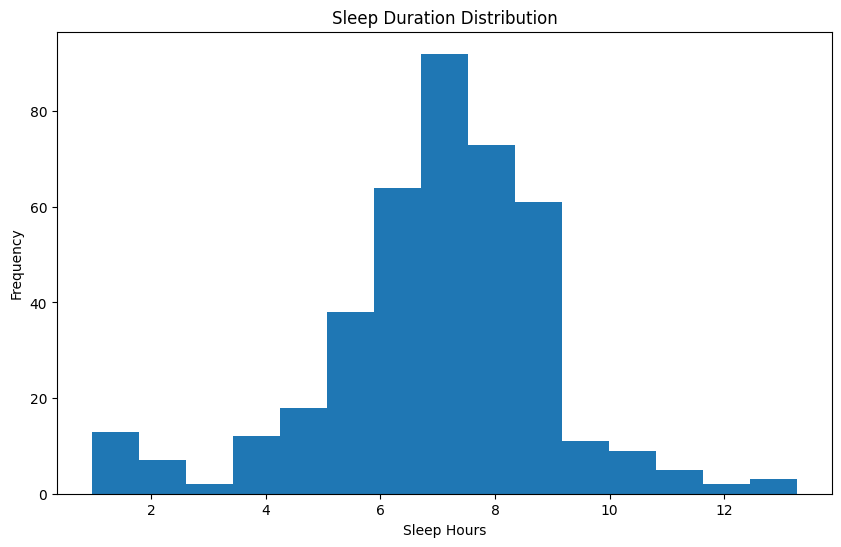

In [31]:
sleep['SleepHours'] = (
    sleep['TotalMinutesAsleep'] / 60
)

plt.figure(figsize=(10,6))

plt.hist(
    sleep['SleepHours'],
    bins=15
)

plt.title('Sleep Duration Distribution')
plt.xlabel('Sleep Hours')
plt.ylabel('Frequency')

plt.show()

### Insight

Sleep duration patterns provide valuable information about user wellness and recovery behavior.

Users with insufficient sleep may benefit from sleep coaching and wellness recommendations.

**E. Steps vs Calories Scatter Plot**

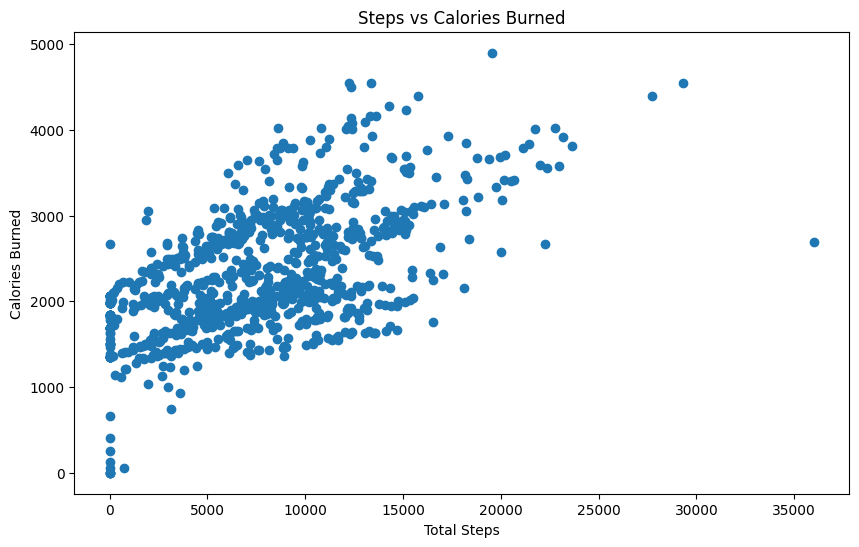

In [32]:
plt.figure(figsize=(10,6))

plt.scatter(
    daily_activity['TotalSteps'],
    daily_activity['Calories']
)

plt.title('Steps vs Calories Burned')
plt.xlabel('Total Steps')
plt.ylabel('Calories Burned')

plt.show()

### Insight

The scatter plot illustrates the relationship between physical activity and calorie expenditure.

A positive relationship suggests that increased movement contributes to higher calorie burn.

**F. Correlation Heatmap**

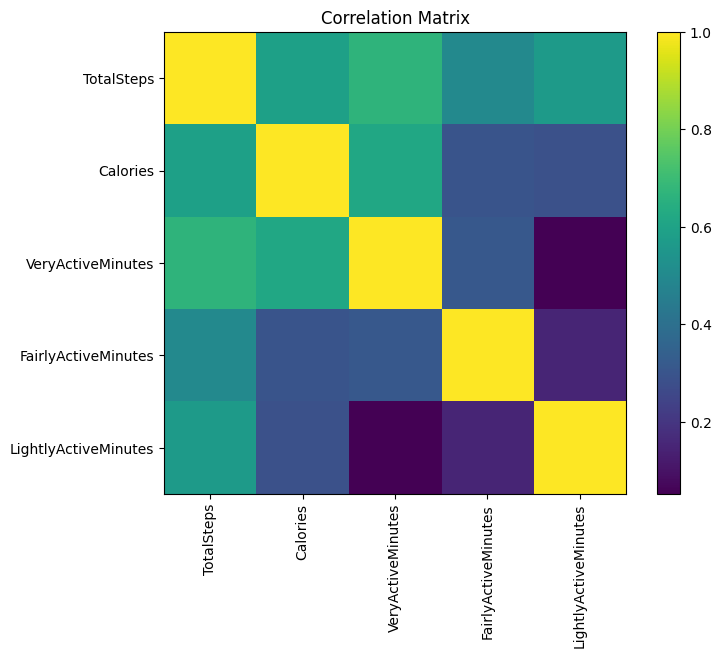

In [33]:
corr_matrix = daily_activity[
[
'TotalSteps',
'Calories',
'VeryActiveMinutes',
'FairlyActiveMinutes',
'LightlyActiveMinutes'
]
].corr()

plt.figure(figsize=(8,6))

plt.imshow(corr_matrix)

plt.colorbar()

plt.xticks(
range(len(corr_matrix.columns)),
corr_matrix.columns,
rotation=90
)

plt.yticks(
range(len(corr_matrix.columns)),
corr_matrix.columns
)

plt.title('Correlation Matrix')

plt.show()

### Insight

The correlation matrix identifies relationships between key fitness metrics and highlights factors that most strongly influence calorie expenditure.

**G. Hourly Activity Trend**

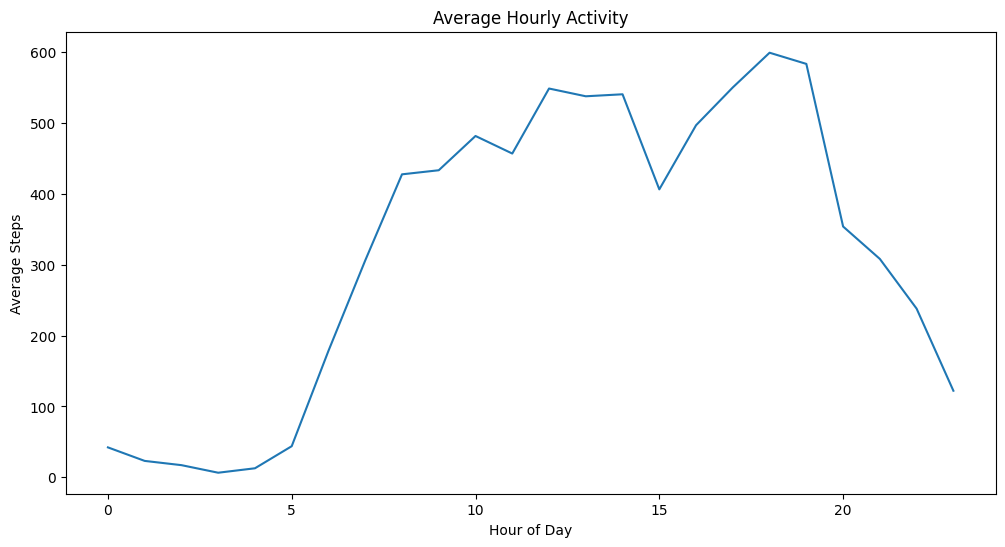

In [34]:
hourly_activity.plot(
    figsize=(12,6)
)

plt.title('Average Hourly Activity')
plt.xlabel('Hour of Day')
plt.ylabel('Average Steps')

plt.show()

### Insight

Understanding peak activity hours helps Bellabeat optimize notification timing, activity reminders, and engagement campaigns.

# Key Findings

1. The average daily step count is below the commonly recommended target of 10,000 steps.

2. Most users fall into the Moderately Active category, while a substantial proportion remain sedentary.

3. Calories burned increase significantly as daily step counts increase.

4. Very Active Minutes show a strong positive relationship with calorie expenditure.

5. User activity levels vary considerably across the dataset.

6. Peak activity occurs during daytime and evening hours.

7. Activity levels are lowest during late-night and early-morning hours.

8. Sleep duration varies significantly among users, indicating diverse sleep habits.

9. Several users record sleep durations below recommended healthy levels.

10. Weight and BMI measurements indicate differences in health and fitness profiles.

11. Highly active users represent a valuable segment for retention and advocacy initiatives.

12. Sedentary users represent an important opportunity for engagement and behavior-change programs.


# Business Insights

The analysis suggests that Bellabeat users exhibit varying levels of physical activity, sleep behavior, and wellness engagement.

Many users are not consistently achieving recommended activity levels, creating opportunities for personalized fitness interventions.

Strong relationships between steps, active minutes, and calorie expenditure demonstrate the value of activity tracking features.

The presence of sedentary users highlights the importance of targeted engagement programs designed to encourage healthier lifestyles.

Sleep behavior analysis indicates potential demand for sleep monitoring and wellness coaching features.

Hourly activity trends provide useful information for optimizing notification schedules and increasing user interaction with the Bellabeat ecosystem.


# Recommendations

## User Engagement

* Introduce achievement badges and reward systems.
* Develop personalized daily step goals.
* Implement inactivity reminders.

## Fitness Challenges

* Launch weekly and monthly step competitions.
* Create community-based fitness challenges.
* Reward consistent activity streaks.

## Sleep Improvement Programs

* Offer bedtime reminders.
* Provide personalized sleep recommendations.
* Develop sleep wellness dashboards.

## Personalized Notifications

* Send reminders during low-activity periods.
* Recommend activity goals based on historical behavior.
* Encourage users to complete daily targets.

## Marketing Strategy

* Segment customers by activity level.
* Target sedentary users with beginner-friendly wellness campaigns.
* Highlight success stories from highly active users.
* Promote Bellabeat's health and wellness ecosystem through personalized messaging.


# Executive Summary

This case study analyzed Bellabeat smart device usage through activity, sleep, weight, and hourly step datasets.

The analysis revealed that many users do not consistently achieve recommended activity levels, while significant differences exist in sleep and fitness behavior.

Strong relationships between physical activity and calorie expenditure demonstrate the effectiveness of activity tracking features.

The findings suggest opportunities for Bellabeat to improve engagement through personalized coaching, fitness challenges, sleep improvement initiatives, and targeted marketing campaigns.

Implementing these recommendations can enhance customer engagement, increase product adoption, and support long-term business growth.

# Conclusion

The Bellabeat Smart Device Usage Analysis successfully identified user behavior patterns related to physical activity, sleep, and wellness tracking.

The study demonstrated that user segmentation, activity monitoring, and behavioral insights can provide valuable guidance for product development and marketing decisions.

By leveraging data-driven strategies such as personalized recommendations, fitness challenges, and wellness programs, Bellabeat can improve user satisfaction, engagement, and retention while strengthening its competitive position in the health technology market.